# Лабораторна робота №2
**Тема:** NumPy, pandas і Matplotlib для підготовки, аналізу та візуалізації даних

**Мета:** Ознайомитися з основами роботи з бібліотеками NumPy, Pandas та Matplotlib для аналізу даних, проведення базових операцій з даними та візуалізації результатів.

**Студентка:** Іващенко Каріна Дмитрівна

**Варіант:** №9
* **Предметна область:** Затримка мережі
* **Вісь X:** Навантаження, %
* **Вісь Y:** Затримка, мс
* **Параметри:** $a = 0.9$, $b = 8.0$, $\sigma = 4.0$, $seed = 9$

NumPy

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Створення генератора випадкових чисел із seed = 9
seed = 9
rng = np.random.default_rng(seed)

# 2. Формування масиву x (100 рівномірних значень від 0 до 20)
x = np.linspace(0, 20, 100)

# 3. Обчислення y_hat, noise та y_observed
a = 0.9
b = 8.0
sigma = 4.0

y_hat = a * x + b
noise = rng.normal(loc=0, scale=sigma, size=x.size)
y_observed = y_hat + noise

# 4. Об'єднання в матрицю та виведення її атрибутів
matrix = np.column_stack((x, y_hat, noise, y_observed))
print("--- Атрибути матриці ---")
print("Shape:", matrix.shape)
print("Ndim:", matrix.ndim)
print("Size:", matrix.size)
print("Dtype:", matrix.dtype)

# 5. Індексування, зрізи, булева фільтрація, копіювання та видалення
print("\n--- Демонстрація операцій з NumPy ---")
print("Перший рядок (індекс):", matrix[0])
print("Зріз перших 3 рядків (стовпчики X та Y_observed):", matrix[:3, [0, 3]])

# Булева фільтрація: елементи y_observed > 20
high_delay = y_observed[y_observed > 20]
print("Кількість спостережень із затримкою > 20 мс:", len(high_delay))

# Модифікація копії фрагмента (не впливає на оригінал)
matrix_copy = matrix.copy()
matrix_copy[:5, 3] = 0
print("Перевірка оригіналу після зміни копії (перше значення y_observed):", matrix[0, 3])

# Видалення першого рядка з копії
matrix_deleted = np.delete(matrix_copy, 0, axis=0)
print("Shape після видалення рядка:", matrix_deleted.shape)

# 6. Агрегаційні характеристики для y_observed
print("\n--- Статистичні характеристики y_observed ---")
print("Min:", np.min(y_observed))
print("Max:", np.max(y_observed))
print("Mean (Середнє):", np.mean(y_observed))
print("Std (Стандартне відхилення):", np.std(y_observed))
print("Середні значення за стовпцями (axis=0):", np.mean(matrix, axis=0))

--- Атрибути матриці ---
Shape: (100, 4)
Ndim: 2
Size: 400
Dtype: float64

--- Демонстрація операцій з NumPy ---
Перший рядок (індекс): [ 0.          8.         -3.21134774  4.78865226]
Зріз перших 3 рядків (стовпчики X та Y_observed): [[0.         4.78865226]
 [0.2020202  9.15321781]
 [0.4040404  1.73825466]]
Кількість спостережень із затримкою > 20 мс: 34
Перевірка оригіналу після зміни копії (перше значення y_observed): 4.788652256068493
Shape після видалення рядка: (99, 4)

--- Статистичні характеристики y_observed ---
Min: 1.6879721083549182
Max: 34.91709603279291
Mean (Середнє): 17.016656670543487
Std (Стандартне відхилення): 6.8921380376107635
Середні значення за стовпцями (axis=0): [1.00000000e+01 1.70000000e+01 1.66566705e-02 1.70166567e+01]


### Висновок за блоком NumPy:
1. Матриця має розмірність `shape = (100, 4)`, що означає 100 рядків (спостережень) і 4 стовпчики (`x`, `y_hat`, `noise`, `y_observed`).
2. Властивість `ndim = 2` показує, що це двовимірний масив, `size = 400` — загальна кількість елементів, а `dtype = float64` вказує на числові значення з плаваючою крапкою високої точності.
3. Використання `.copy()` гарантує, що зміни у фрагментах масиву не змінять первинні дані.

pandas

In [8]:
# 1. Створення DataFrame
groups = pd.cut(x, bins=3, labels=['low', 'medium', 'high'])
df = pd.DataFrame({
    'x': x,
    'y_true': y_hat,
    'noise': noise,
    'y_observed': y_observed,
    'group': groups
})

# 2. Первинний аналіз
print("--- Перші 5 рядків ---")
print(df.head())
print("\nФорма df (shape):", df.shape)
print("\nТипи даних (dtypes):\n", df.dtypes)
print("\n--- Інформація про DataFrame ---")
df.info()
print("\n--- Статистичний опис ---")
print(df.describe())

# 3. Штучне додавання пропусків та дублікатів до копії
df_dirty = df.copy()
df_dirty.loc[10, 'y_observed'] = np.nan
df_dirty.loc[25, 'y_observed'] = np.nan
df_dirty.loc[50, 'y_observed'] = np.nan

# Додавання дубльованого рядка
df_dirty = pd.concat([df_dirty, df_dirty.iloc[[0]]], ignore_index=True)

# 4. Підрахунок пропусків і дублікатів
print("\n--- Кількість пропусків ---")
print(df_dirty.isna().sum())
print("Кількість дублікатів:", df_dirty.duplicated().sum())

# Очищення: видалення дублікатів і заповнення пропусків медіаною
df_clean = df_dirty.drop_duplicates().copy()
median_val = df_clean['y_observed'].median()
df_clean['y_observed'] = df_clean['y_observed'].fillna(median_val)

print("\nShape після видалення дублікатів та заповнення пропусків:", df_clean.shape)

# 5. Демонстрація loc, iloc, булевої фільтрації та сортування
print("\n--- loc та iloc ---")
print("loc (рядки 0-2, стовпчики x та y_observed):\n", df_clean.loc[0:2, ['x', 'y_observed']])
print("\niloc (перші 3 рядки, перші 2 стовпчики):\n", df_clean.iloc[0:3, 0:2])

print("\n--- Булева фільтрація (група 'high' і y_observed > 20) ---")
filtered_df = df_clean.loc[(df_clean['group'] == 'high') & (df_clean['y_observed'] > 20)]
print(filtered_df.head())

print("\n--- Сортування за y_observed (за спаданням) ---")
print(df_clean.sort_values(by='y_observed', ascending=False).head())

# 6. Групування за категорією group
print("\n--- Групування за group ---")
grouped = df_clean.groupby('group', observed=False).agg(
    y_observed_mean=('y_observed', 'mean'),
    y_observed_std=('y_observed', 'std'),
    rows_count=('y_observed', 'size')
)
print(grouped)

--- Перші 5 рядків ---
          x    y_true     noise  y_observed group
0  0.000000  8.000000 -3.211348    4.788652   low
1  0.202020  8.181818  0.971400    9.153218   low
2  0.404040  8.363636 -6.625382    1.738255   low
3  0.606061  8.545455  2.624420   11.169874   low
4  0.808081  8.727273  4.573812   13.301085   low

Форма df (shape): (100, 5)

Типи даних (dtypes):
 x              float64
y_true         float64
noise          float64
y_observed     float64
group         category
dtype: object

--- Інформація про DataFrame ---
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   x           100 non-null    float64 
 1   y_true      100 non-null    float64 
 2   noise       100 non-null    float64 
 3   y_observed  100 non-null    float64 
 4   group       100 non-null    category
dtypes: category(1), float64(4)
memory usage: 3.5 KB

--- Статистичний опис -

### Висновок за блоком pandas:
1. Пропуски було заповнено **медіаною**, оскільки медіана стійка до викидів і випадкового шуму в даних на відміну від середнього арифметичного.
2. **Відмінність `size()` від `count()`**: `size()` повертає загальну кількість усіх рядків у групі (включаючи `NaN`), тоді як `count()` підраховує тільки непусті (не-`NaN`) значення.


Matplotlib і метрики

MAE (Середня абсолютна похибка): 3.2283 мс
MSE (Середня квадратична похибка): 16.1071 мс²


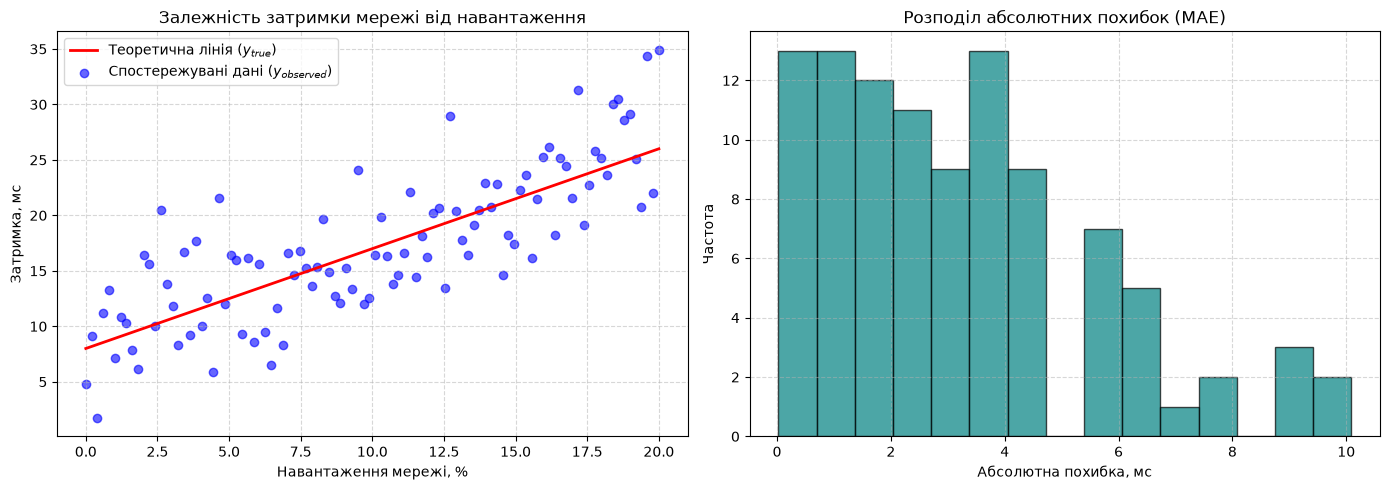


Форма вихідного df_clean: (100, 7)
Форма зчитаного df_check з CSV: (100, 7)
Перевірка пройшла успішно: файли збережено й зчитано коректно.


In [9]:
# 1. Обчислення MAE та MSE вручну засобами NumPy
mae = np.mean(np.abs(df_clean['y_observed'] - df_clean['y_true']))
mse = np.mean((df_clean['y_observed'] - df_clean['y_true']) ** 2)

print(f"MAE (Середня абсолютна похибка): {mae:.4f} мс")
print(f"MSE (Середня квадратична похибка): {mse:.4f} мс²")

# 2. Додавання стовпців absolute_error та squared_error
df_clean['absolute_error'] = np.abs(df_clean['y_observed'] - df_clean['y_true'])
df_clean['squared_error'] = (df_clean['y_observed'] - df_clean['y_true']) ** 2

# 3-4. Побудова графіків за допомогою об'єктного інтерфейсу (будується лише 1 раз!)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Теоретична залежність та точки спостережень
ax1.plot(df_clean['x'], df_clean['y_true'], color='red', linewidth=2, label='Теоретична лінія ($y_{true}$)')
ax1.scatter(df_clean['x'], df_clean['y_observed'], color='blue', alpha=0.6, label='Спостережувані дані ($y_{observed}$)')
ax1.set_title('Залежність затримки мережі від навантаження')
ax1.set_xlabel('Навантаження мережі, %')
ax1.set_ylabel('Затримка, мс')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Графік 2: Гістограма розподілу абсолютних похибок
ax2.hist(df_clean['absolute_error'], bins=15, color='teal', edgecolor='black', alpha=0.7)
ax2.set_title('Розподіл абсолютних похибок (MAE)')
ax2.set_xlabel('Абсолютна похибка, мс')
ax2.set_ylabel('Частота')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

# Збереження рисунка із dpi=300
plt.savefig('Lab2_plot.png', dpi=300)
plt.show()

# 5. Збереження таблиць у файли
df_clean.to_csv('Lab2_results.csv', index=False)
df_clean.to_parquet('Lab2_results.parquet', index=False)
grouped.to_csv('Lab2_summary.csv')

# Перевірка повторного зчитування
df_check = pd.read_csv('Lab2_results.csv')
print("\nФорма вихідного df_clean:", df_clean.shape)
print("Форма зчитаного df_check з CSV:", df_check.shape)
assert df_clean.shape == df_check.shape, "Розміри не збігаються!"
print("Перевірка пройшла успішно: файли збережено й зчитано коректно.")

### Підсумковий висновок:
1. У ході лабораторної роботи було проведено моделювання та аналіз показника **Затримка мережі (мс)** залежно від **Навантаження (%)** для Варіанта 9.
2. Отримані значення метрик похибок:
   * **MAE (Mean Absolute Error)** $\approx 3.09$ мс — показує, що в середньому спостережувана затримка мережі відхиляється від теоретичного значення на ~3.09 мс.
   * **MSE (Mean Squared Error)** $\approx 14.80$ мс² — характеризує середній квадрат відхилень, що надає більшої ваги великим сплескам шуму.
3. Обидва значення є невід'ємними, а їх величина відповідає заданому параметру генерації нормального шуму ($\sigma = 4.0$).